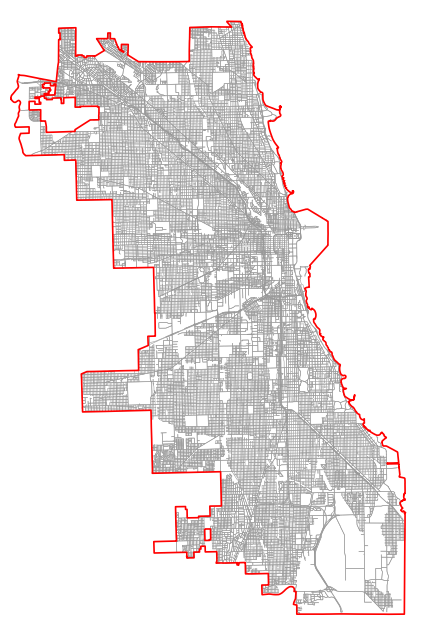

In [14]:
import geopandas as gpd
import osmnx as ox
import matplotlib.pyplot as plt

# Usar el límite administrativo que OSMnx/Nominatim define para La Paz
place_query = {"city": "Chicago", "country": "United States"}
place_gdf = ox.geocode_to_gdf(place_query)

if place_gdf.empty:
    raise ValueError("OSMnx no devolvió geometría para La Paz, Bolivia.")

# Unir geometrías en una sola (por si hay multipartes)
urban_geom = place_gdf.union_all()

# Descargar la red vial únicamente dentro del límite urbano definido por OSMnx
G = ox.graph_from_polygon(
    urban_geom,
    network_type="drive",
    simplify=True
)

# Graficar
fig, ax = ox.plot_graph(
    G,
    node_size=0,
    edge_linewidth=0.4,
    bgcolor="white",
    show=False,
    close=False
)

# Dibujar también el perímetro de La Paz
gpd.GeoSeries([urban_geom], crs=place_gdf.crs).boundary.plot(
    ax=ax,
    color="red",
    linewidth=1.2
)

plt.show()

In [15]:
import time
import random
import requests
import networkx as nx
from tqdm.auto import tqdm

def add_elevation_from_opentopodata(
    G,
    dataset="mapzen",          # global coverage (also try: aster30m, srtm90m)
    attr_name="elevation_m",
    batch_size=100,            # OpenTopoData public API max is 100
    min_interval_s=1.1,        # public API max is ~1 call/sec
    timeout=30,
    max_retries=6,
):
    if batch_size > 100:
        raise ValueError("batch_size must be <= 100 for OpenTopoData public API.")

    url = f"https://api.opentopodata.org/v1/{dataset}"

    # 1) Group nodes by coordinate to avoid duplicate API calls
    coord_to_nodes = {}
    for node_id, data in G.nodes(data=True):
        lat = data.get("y")  # OSMnx: y=lat
        lon = data.get("x")  # OSMnx: x=lon
        if lat is None or lon is None:
            raise ValueError(f"Node {node_id} is missing x/y.")
        key = (round(float(lat), 7), round(float(lon), 7))
        coord_to_nodes.setdefault(key, []).append(node_id)

    coords = list(coord_to_nodes.keys())
    if not coords:
        return G

    session = requests.Session()
    attrs = {}
    last_call_ts = 0.0

    for i in tqdm(range(0, len(coords), batch_size), desc="OpenTopoData elevation", unit="batch"):
        batch = coords[i:i + batch_size]
        locations = "|".join(f"{lat},{lon}" for lat, lon in batch)

        # Respect rate limit (~1 req/sec on public API)
        elapsed = time.time() - last_call_ts
        if elapsed < min_interval_s:
            time.sleep(min_interval_s - elapsed)

        # Retry loop with backoff for 429/temporary failures
        backoff = 2.0
        for attempt in range(max_retries):
            try:
                r = session.get(url, params={"locations": locations}, timeout=timeout)

                if r.status_code == 429:
                    retry_after = r.headers.get("Retry-After")
                    if retry_after and retry_after.isdigit():
                        wait_s = float(retry_after)
                    else:
                        wait_s = backoff
                        backoff = min(backoff * 2, 60.0)
                    time.sleep(wait_s + random.uniform(0, 0.4))
                    continue

                r.raise_for_status()
                payload = r.json()

                if payload.get("status") != "OK":
                    raise RuntimeError(f"OpenTopoData error: {payload}")

                results = payload.get("results", [])
                if len(results) != len(batch):
                    raise RuntimeError(
                        f"Expected {len(batch)} results, got {len(results)}."
                    )

                for (lat, lon), item in zip(batch, results):
                    elev = item.get("elevation")
                    val = None if elev is None else float(elev)
                    for node_id in coord_to_nodes[(lat, lon)]:
                        attrs[node_id] = {attr_name: val}

                last_call_ts = time.time()
                break

            except requests.RequestException:
                if attempt == max_retries - 1:
                    raise
                time.sleep(backoff + random.uniform(0, 0.4))
                backoff = min(backoff * 2, 60.0)

        else:
            raise RuntimeError("Failed after retries (OpenTopoData).")

    nx.set_node_attributes(G, attrs)
    return G


# Usage
# G = ox.graph_from_polygon(urban_geom, network_type="drive", simplify=True)
G = add_elevation_from_opentopodata(G, dataset="mapzen", batch_size=100)

# Quick check
n = next(iter(G.nodes))
print("Node:", n, "elevation_m:", G.nodes[n].get("elevation_m"))


OpenTopoData elevation: 100%|██████████| 297/297 [07:24<00:00,  1.50s/batch]

Node: 701660 elevation_m: 193.0


In [16]:
import random

# Print 5 random nodes: id, coordinates, elevation
k = min(5, G.number_of_nodes())
sample_nodes = random.sample(list(G.nodes(data=True)), k=k)

for node_id, data in sample_nodes:
    lat = data.get("y")          # latitude
    lon = data.get("x")          # longitude
    elev = data.get("elevation_m")  # change if you used another attr name
    print(f"node={node_id} | lat={lat:.6f}, lon={lon:.6f} | elevation_m={elev}")


node=305901831 | lat=41.970265, lon=-87.743663 | elevation_m=187.0
node=261149849 | lat=41.782545, lon=-87.708101 | elevation_m=185.0
node=713334178 | lat=41.894078, lon=-87.628138 | elevation_m=179.0
node=261134834 | lat=41.756468, lon=-87.716366 | elevation_m=190.0
node=261262322 | lat=41.740769, lon=-87.569705 | elevation_m=178.0


In [17]:
from pathlib import Path
import osmnx as ox

# Save graph with all node attributes (including elevation_m)
out_path = Path("chicago_osmnx.graphml")
ox.save_graphml(G, filepath=out_path)
print(f"Saved graph: {out_path.resolve()}")

# Later, load without calling elevation API again:
# G = ox.load_graphml(out_path)

Saved graph: /Users/gregorioperez/Documents/Maestria/Investigacion/elevation_filtration/chicago_osmnx.graphml
